In [2]:
import numpy as np
import os
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import trange
from scipy.optimize import minimize
from scipy.linalg import orth
from tqdm import trange
import importlib
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from scipy.interpolate import CubicSpline, RectBivariateSpline
from matplotlib.path import Path

device = "cuda" if torch.cuda.is_available() else "cpu"

In [4]:
class TwoLayerMLP(nn.Module):
    def __init__(self, latent_dim=64, num_noise_sources = 8, proj_dim = 2):
        super().__init__()
        self.Gamma = nn.Linear(proj_dim, latent_dim, bias=False)   
        self.input_bias = nn.Parameter(torch.zeros(latent_dim))  
        self.W_s = nn.Linear(latent_dim, proj_dim, bias= False)
        self.I_s = nn.Parameter(torch.zeros(proj_dim))
        self.B_s = nn.Parameter(torch.randn(proj_dim, num_noise_sources))

    def forward(self, x):
        z = self.Gamma(x) + self.input_bias       
        z = torch.tanh(z)
        out = -x + self.W_s(z) + self.I_s  
        return out

In [6]:
latent_dim = 512
model = TwoLayerMLP(latent_dim, proj_dim = 3).to(device)

params = torch.load('../lorenz_rnn.pt', weights_only=False)

W = torch.tensor(params['W'])
Gamma = torch.tensor(params['Gamma'])
I = torch.tensor(params['I'])
B = torch.tensor(params['B'])
b = torch.tensor(params['b'])
Gamma_pinv = torch.tensor(params['Gamma_pinv'])

In [7]:
def integrate_rnn(W, I, B, dt, T, u0):

    latent_dim = W.shape[0]
    num_noise_sources = B.shape[1]
    Nt = int(T/dt)
    
    u = torch.zeros((latent_dim,Nt))
    u[:, 0] = u0

    for t in trange(0,Nt-1):
        u_ = u[:, t]
        u[:, t+1] = u_ + dt*(-u_ + W@torch.tanh(u_) + I) + np.sqrt(dt)*B@torch.randn((num_noise_sources,))

    return u

def project_rnn(u, Gamma, b, Gamma_pinv):
    return Gamma_pinv@((u.T - b).T)

def proj(u):
    return project_rnn(u, Gamma, b, Gamma_pinv)

In [8]:
y0 = torch.tensor([0.0, 0.0, 0.0], dtype=torch.float32, device=Gamma.device)

dt = 0.0001; T = 100; u0 = Gamma @ y0 + b; Nt = int(T/dt)

u = integrate_rnn(W, I, B, dt, T, u0)

y = project_rnn(u, Gamma, b, Gamma_pinv)

100%|████████████████████████████████| 999999/999999 [00:34<00:00, 29175.55it/s]


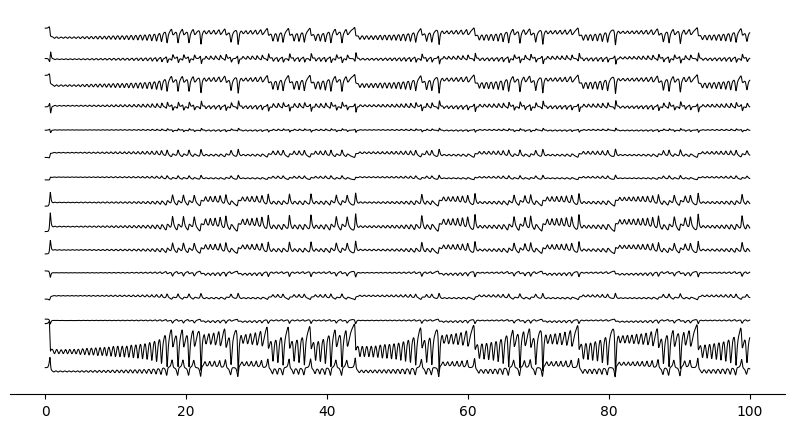

In [9]:
fig, ax = plt.subplots(1,1)
fig.set_size_inches(10,5)

t = np.linspace(0,T,Nt)

ds = 10
num_vis_neurons = 15
vis_neurons = np.random.choice(range(0,latent_dim),num_vis_neurons, replace=False)

for n, v in enumerate(vis_neurons):
    trace = u[v, 100::ds] + 25*n - torch.mean(u[v, :])
    ax.plot(t[100::ds],trace, 'black', linewidth = 0.75)
sns.despine(left = True)
plt.gca().get_yaxis().set_visible(False)
plt.show()

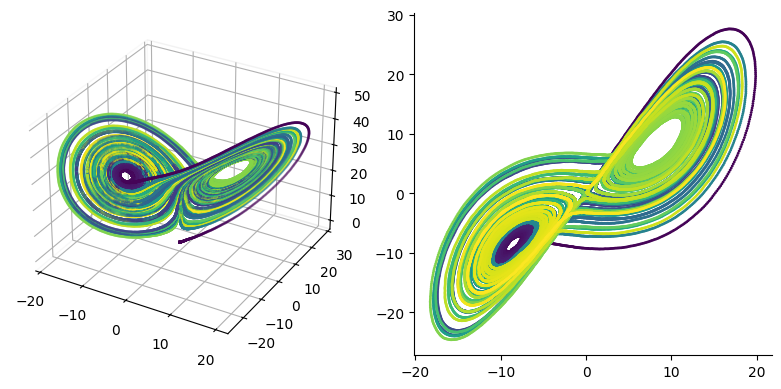

In [10]:
fig = plt.figure(figsize=(8,4))
ax = fig.add_subplot(121, projection='3d')
ax1 = fig.add_subplot(122)
time = np.linspace(0,T,int(T/dt))
ds = 10
ax.scatter(y[0,::ds], y[1,::ds], y[2,::ds], c=time[::ds], cmap='viridis', s=1)
ax1.scatter(y[0,::ds], y[1,::ds],c=time[::ds], cmap='viridis', s=1)
ax.xaxis.pane.fill = False
ax.yaxis.pane.fill = False
ax.zaxis.pane.fill = False
sns.despine()
plt.tight_layout()
plt.show()

In [8]:
mu = torch.mean(u, axis = 1)
X = (u.T - mu).T # centered
X_np = X.numpy()
C = np.cov(X_np)
eig_vals, eig_vecs = np.linalg.eig(C)
idx = np.flip(np.argsort(eig_vals))
U = eig_vecs[:, idx]
S_squared = eig_vals[idx]

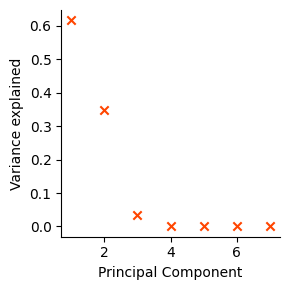

In [9]:
total_var = np.sum(S_squared)
var_explained = S_squared / total_var          
cum_var_explained = np.cumsum(var_explained)

comps = 7
indices = np.arange(1, comps+1)

fig, ax = plt.subplots(1,1)
fig.set_size_inches(3,3)

ax.scatter(indices, var_explained[:comps], marker = 'x', color = 'orangered')
ax.set_xlabel('Principal Component')
ax.set_ylabel('Variance explained')

sns.despine()
plt.tight_layout()
plt.show()

In [10]:
U_torch = torch.from_numpy(U).to(X.dtype)
Z = (X.T @ U_torch[:,:3]).T

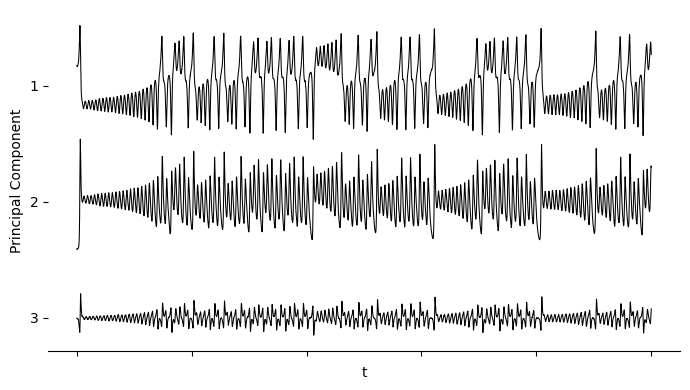

In [19]:
fig, ax = plt.subplots(1,1)
fig.set_size_inches(7,4)

t = np.linspace(0,T,Nt)

ds = 10
num_vis_neurons = 3

for n in range(num_vis_neurons):
    trace = Z[n,100::ds] - 200*n - torch.mean(Z[n, :])
    ax.plot(t[100::ds],trace, 'black', linewidth = 0.75)
sns.despine(left = True)
#plt.gca().get_yaxis().set_visible(False)
ax.set_yticks(list(-200*np.arange(num_vis_neurons)))
ax.set_yticklabels(list(np.arange(num_vis_neurons)+1))
ax.set_xticklabels([])
ax.set_ylabel('Principal Component')
ax.set_xlabel(r't')
plt.tight_layout()
plt.show()

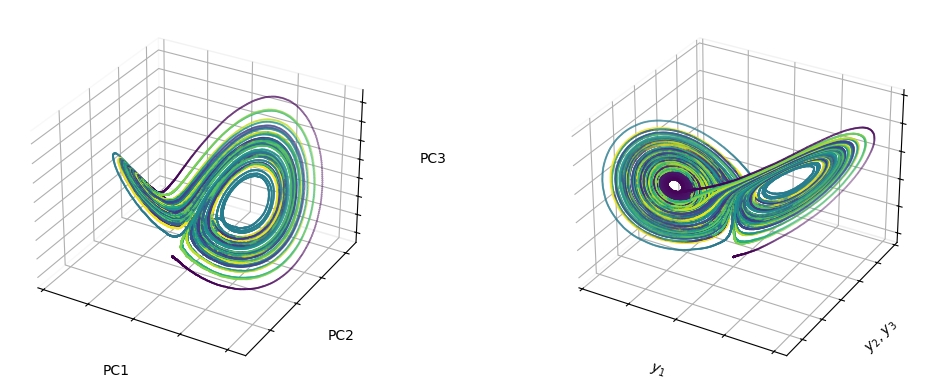

In [33]:
fig = plt.figure(figsize=(12,4))
ax = fig.add_subplot(121, projection='3d')
ax1 = fig.add_subplot(122, projection='3d')
time = np.linspace(0,T,int(T/dt))
ds = 10

ax1.scatter(y[0,::ds], y[1,::ds], y[2,::ds], c=time[::ds], cmap='viridis', s=0.2, rasterized=True)
ax.scatter(Z[0,::ds], Z[1,::ds], Z[2,::ds], c=time[::ds], cmap='viridis', s=0.2, rasterized=True)

ax.set_xlabel('PC1')
ax.set_ylabel('PC2')
ax.set_zlabel('PC3')
ax.set_zlabel('PC3', labelpad=12)      # extra padding

ax1.set_xlabel(r'$y_1$')
ax1.set_ylabel(r'$y_2$, $y_3$')
ax1.set_zlabel(r'$y_3$', labelpad=18)
ax1.zaxis.set_rotate_label(False)      
ax1.zaxis.label.set_rotation(90) 

ax.xaxis.pane.fill = False
ax.yaxis.pane.fill = False
ax.zaxis.pane.fill = False

ax1.xaxis.pane.fill = False
ax1.yaxis.pane.fill = False
ax1.zaxis.pane.fill = False

ax.set_xticklabels([])
ax.set_yticklabels([])
ax.set_zticklabels([])
ax1.set_xticklabels([])
ax1.set_yticklabels([])
ax1.set_zticklabels([])
sns.despine()

plt.tight_layout()
plt.show()

We want to see if these can be mapped onto each other by an affine linear transformation. So we solve the equation,

$$
\Gamma \approx U_d \Xi
$$

And use this to transform our data $\Xi Z$. But it is still zero-centred.

In [128]:
Xi, residuals, rank, s = np.linalg.lstsq(Gamma.numpy(), U[:,:3], rcond=None)
z_trans = torch.from_numpy(Xi).to(X.dtype)@Z[:3,:]

So we still have to solve the equation

$$
\Gamma = (\mu_u - b)\mu_y
$$
and then add $\mu_y$ back on.

In [134]:
mu_u_np = mu.numpy()         
b_np = b.numpy()              
mu_y_np, *_ = np.linalg.lstsq(Gamma.numpy(), mu_u_np - b_np, rcond=None)
mu_y = torch.from_numpy(mu_y_np).to(X.dtype)  # (3,)
y_hat = z_trans + mu_y[:, None]   # (3, T)

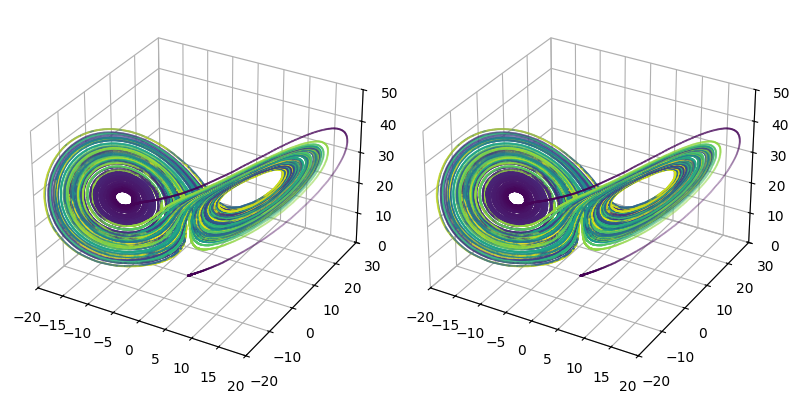

In [135]:
fig = plt.figure(figsize=(8,4))
ax = fig.add_subplot(121, projection='3d')
ax1 = fig.add_subplot(122, projection='3d')
time = np.linspace(0,T,int(T/dt))
ds = 10

ax.scatter(y[0,::ds], y[1,::ds], y[2,::ds], c=time[::ds], cmap='viridis', s=0.2)
ax1.scatter(y_hat[0,::ds], y_hat[1,::ds], y_hat[2,::ds], c=time[::ds], cmap='viridis', s=0.2)

ax.set_xlim([-20,20])
ax1.set_xlim([-20,20])
ax.set_ylim([-20,30])
ax1.set_ylim([-20,30])
ax.set_zlim([0,50])
ax1.set_zlim([0,50])

ax.xaxis.pane.fill = False
ax.yaxis.pane.fill = False
ax.zaxis.pane.fill = False

ax1.xaxis.pane.fill = False
ax1.yaxis.pane.fill = False
ax1.zaxis.pane.fill = False

sns.despine()
plt.tight_layout()
plt.show()

So we can recover the affine subspace up to a linear transformation.